## Heart Failure Prediction 

This notebook applies machine learning techniques to predict heart failure using a set of clinical and demographic patient features. The main goal of this work is to build models that can classify whether a patient is likely to have heart disease based on measurable medical indicators. The process begins with exploring the dataset, understanding the meaning of each feature, and preparing the data through cleaning, encoding, and scaling.

By analyzing patterns in the data, machine learning helps identify which clinical factors contribute most to heart disease risk. After preprocessing, several classification models are trained and evaluated to determine which algorithm provides the most accurate and reliable predictions. This approach supports early detection and can assist in improving medical decision‑making.

**Description of the variables of the data used here**



•Age — The age of the patient in years. It is an important numerical feature related to heart disease risk.

• Sex — The biological sex of the patient (M = Male, F = Female). Used to analyze gender‑based differences in heart disease.

• ChestPainType — The type of chest pain experienced by the patient (ATA, NAP, ASY, TA). This feature helps identify possible cardiac conditions.

• RestingBP — Resting blood pressure measured in mm Hg. High values may indicate cardiovascular issues.

• Cholesterol — Serum cholesterol level in mg/dL. Elevated cholesterol is a major risk factor for heart disease.

• FastingBS — Fasting blood sugar (0 = < 120 mg/dL, 1 = ≥ 120 mg/dL). Indicates whether the patient has high fasting glucose.

• RestingECG — Resting electrocardiogram results (Normal, ST, LVH). Used to detect abnormalities in heart electrical activity.

• MaxHR — Maximum heart rate achieved during exercise. Reflects cardiovascular fitness and stress response.

• ExerciseAngina — Exercise‑induced angina (Y = Yes, N = No). Indicates whether the patient experiences chest pain during physical activity.

• Oldpeak — ST depression induced by exercise relative to rest. Helps assess the severity of ischemia.

• ST_Slope — The slope of the ST segment during peak exercise (Up, Flat, Down). Used to evaluate heart stress response.

• HeartDisease — Target variable (0 = No heart disease, 1 = Heart disease). This is the outcome the model aims to predict.

## Section 1. Data Load & inspection


**Import libraries**


In [1]:
# استيراد مكتبة pandas / Import pandas for data manipulation
import pandas as pd

# استيراد مكتبة numpy / Import numpy for numerical operations
import numpy as np

# استيراد مكتبة matplotlib / Import matplotlib for plotting
import matplotlib.pyplot as plt

# استيراد مكتبة seaborn / Import seaborn for statistical visualizations
import seaborn as sns

# استيراد دالة تقسيم البيانات / Import train_test_split for splitting data
from sklearn.model_selection import train_test_split

# استيراد أداة تقييس البيانات / Import StandardScaler for feature scaling
from sklearn.preprocessing import StandardScaler

# استيراد مقاييس التقييم / Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# استيراد نموذج الانحدار اللوجستي / Import Logistic Regression model
from sklearn.linear_model import LogisticRegression

# استيراد نموذج الغابة العشوائية / Import Random Forest model
from sklearn.ensemble import RandomForestClassifier

**1. Load the Heart Failure Dataset**


In [2]:
# تحميل البيانات من المسار الصحيح / Load dataset from correct path
df = pd.read_csv("/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv")

Summary: In this step, we imported the dataset from the correct directory to begin the analysis process.
الملخص: في هذه الخطوة قمنا بتحميل البيانات من المسار الصحيح لبدء عملية التحليل.

**2. Preview Data**


In [3]:
# عرض أول 5 صفوف / Preview first 5 rows
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Summary: This step displays the first five rows of the dataset to help understand its structure and verify that the data was loaded correctly.
الملخص: في هذه الخطوة قمنا بعرض أول خمس صفوف من البيانات لفهم شكلها والتأكد من تحميلها بشكل صحيح.

**3. Dataset Shape**


In [4]:
# عرض عدد الصفوف والأعمدة / Show shape
df.shape

(918, 12)

Summary: The dataset shape shows the total number of rows and columns, helping identify the dataset size and understand how much data is available for analysis.
الملخص: يوضّح شكل البيانات عدد الصفوف والأعمدة، مما يساعد على معرفة حجم البيانات ومدى كفايتها للتحليل.


**4. Data Information**

In [5]:
# عرض معلومات البيانات / Show info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


Summary: The info() output provides details about each column, including data types and whether any missing values exist, helping assess data quality before preprocessing.
الملخص: يعرض أمر info() أنواع البيانات في كل عمود ويكشف وجود قيم مفقودة، مما يساعد على تقييم جودة البيانات قبل معالجتها.


**5. Statistical Summary**

In [6]:
# عرض الإحصائيات / Show statistics
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Summary: The descriptive statistics summarize numerical features by showing metrics such as mean, minimum, maximum, and standard deviation, offering an initial understanding of data distribution.
الملخص: تقدّم الإحصاءات الوصفية نظرة أولية على المتغيرات العددية من خلال عرض المتوسط، والانحراف المعياري، وأقل وأعلى قيمة، مما يساعد على فهم توزيع البيانات.


## Section 2. Exploratory Data Analysis & Visualization

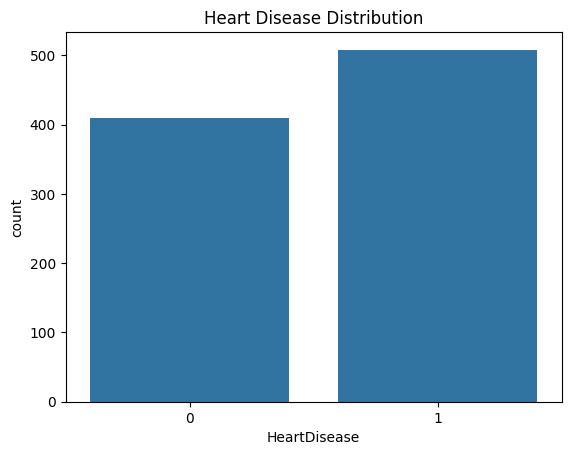

In [7]:

# عرض توزيع مرض القلب / Visualize heart disease distribution
sns.countplot(x='HeartDisease', data=df)

plt.title('Heart Disease Distribution')

plt.show()

الملخص: يوضح هذا الكود عدد المرضى المصابين وغير المصابين بمرض القلب، ويساعد على معرفة ما إذا كانت البيانات متوازنة، وهذا مهم لبناء نماذج تعلم آلة دقيقة.

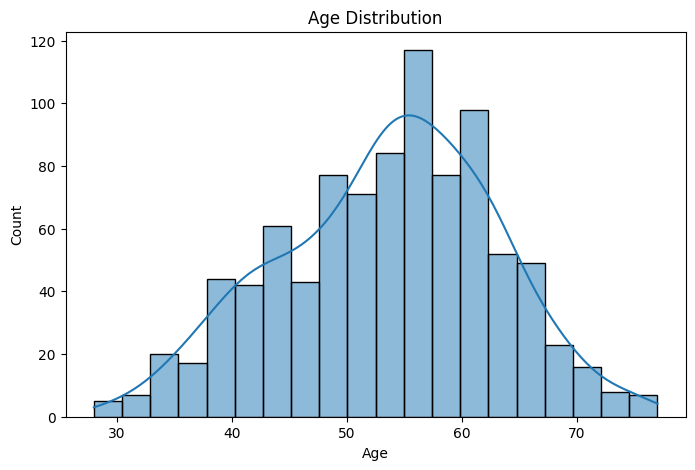

In [8]:
# توزيع الأعمار / Age distribution
plt.figure(figsize=(8,5))

sns.histplot(df['Age'], bins=20, kde=True)

plt.title('Age Distribution')

plt.xlabel('Age')

plt.ylabel('Count')

plt.show()

الملخص: يعرض هذا الكود توزيع أعمار المرضى، ويساعد على معرفة الفئة العمرية الأكثر شيوعًا في مجموعة البيانات.

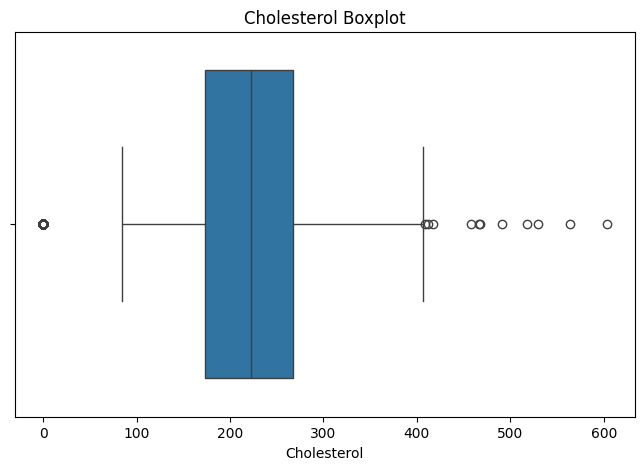

In [9]:
# توزيع الكوليسترول واكتشاف القيم الشاذة / Cholesterol distribution and outliers
plt.figure(figsize=(8,5))

sns.boxplot(x=df['Cholesterol'])

plt.title('Cholesterol Boxplot')

plt.show()

الملخص: يوضح هذا الكود توزيع قيم الكوليسترول، ويساعد على اكتشاف القيم الشاذة أو القيم غير الطبيعية في البيانات.

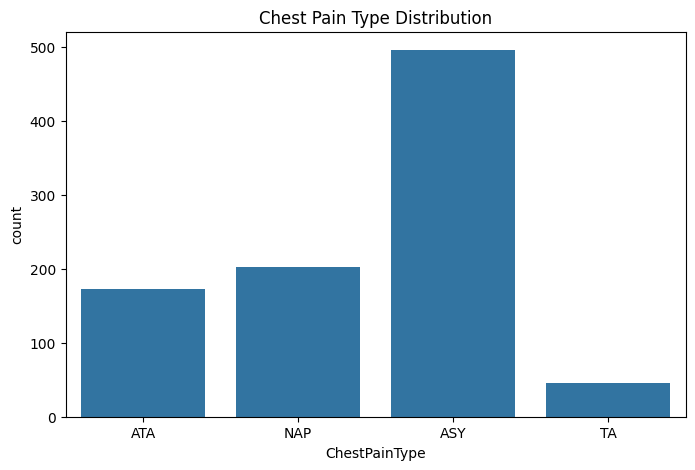

In [10]:
# توزيع أنواع ألم الصدر / Chest pain type distribution
plt.figure(figsize=(8,5))

sns.countplot(x='ChestPainType', data=df)

plt.title('Chest Pain Type Distribution')

plt.show()

الملخص: يوضح هذا الكود عدد المرضى في كل نوع من أنواع ألم الصدر، ويساعد على معرفة النوع الأكثر انتشارًا بين المرضى.

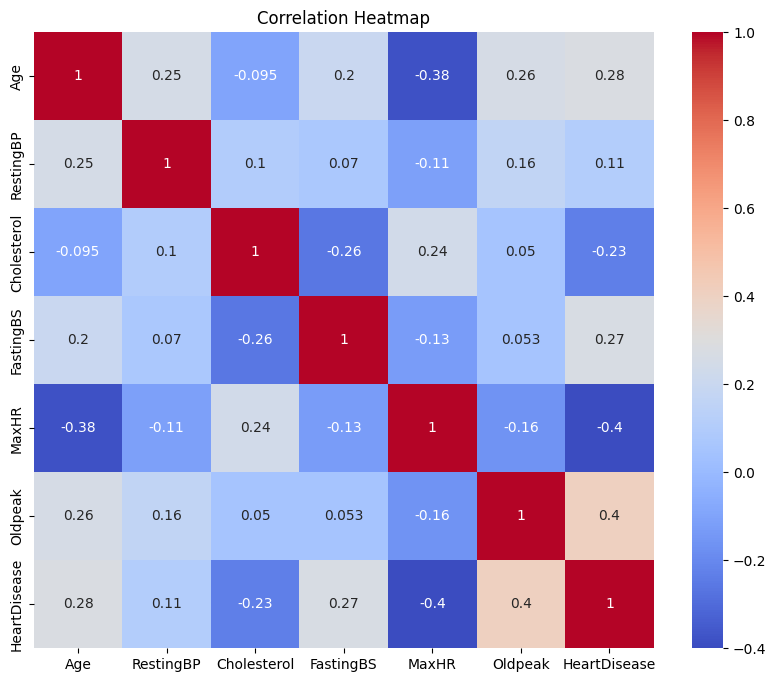

In [11]:
# خريطة الارتباط بين المتغيرات / Correlation heatmap
plt.figure(figsize=(10,8))

numeric_df = df.select_dtypes(include=['int64', 'float64'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

الملخص: يوضح هذا الكود العلاقات بين المتغيرات العددية في البيانات، ويساعد على معرفة المتغيرات المرتبطة بمرض القلب بشكل إيجابي أو سلبي.

## Section 3: Data Cleaning & Preprocessing

**1. Checking for Missing Values**

In [12]:
# فحص القيم المفقودة  (NaN)
print("Missing Values: ")
print(df.isnull().sum())


Missing Values: 
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


الملخص: يوضح هذا الكود فحص وجود القيم المفقودة في جميع أعمدة البيانات، واالتأكد من اكتمال البيانات وجاهزيتها

**2. Checking and Handling Outliers**

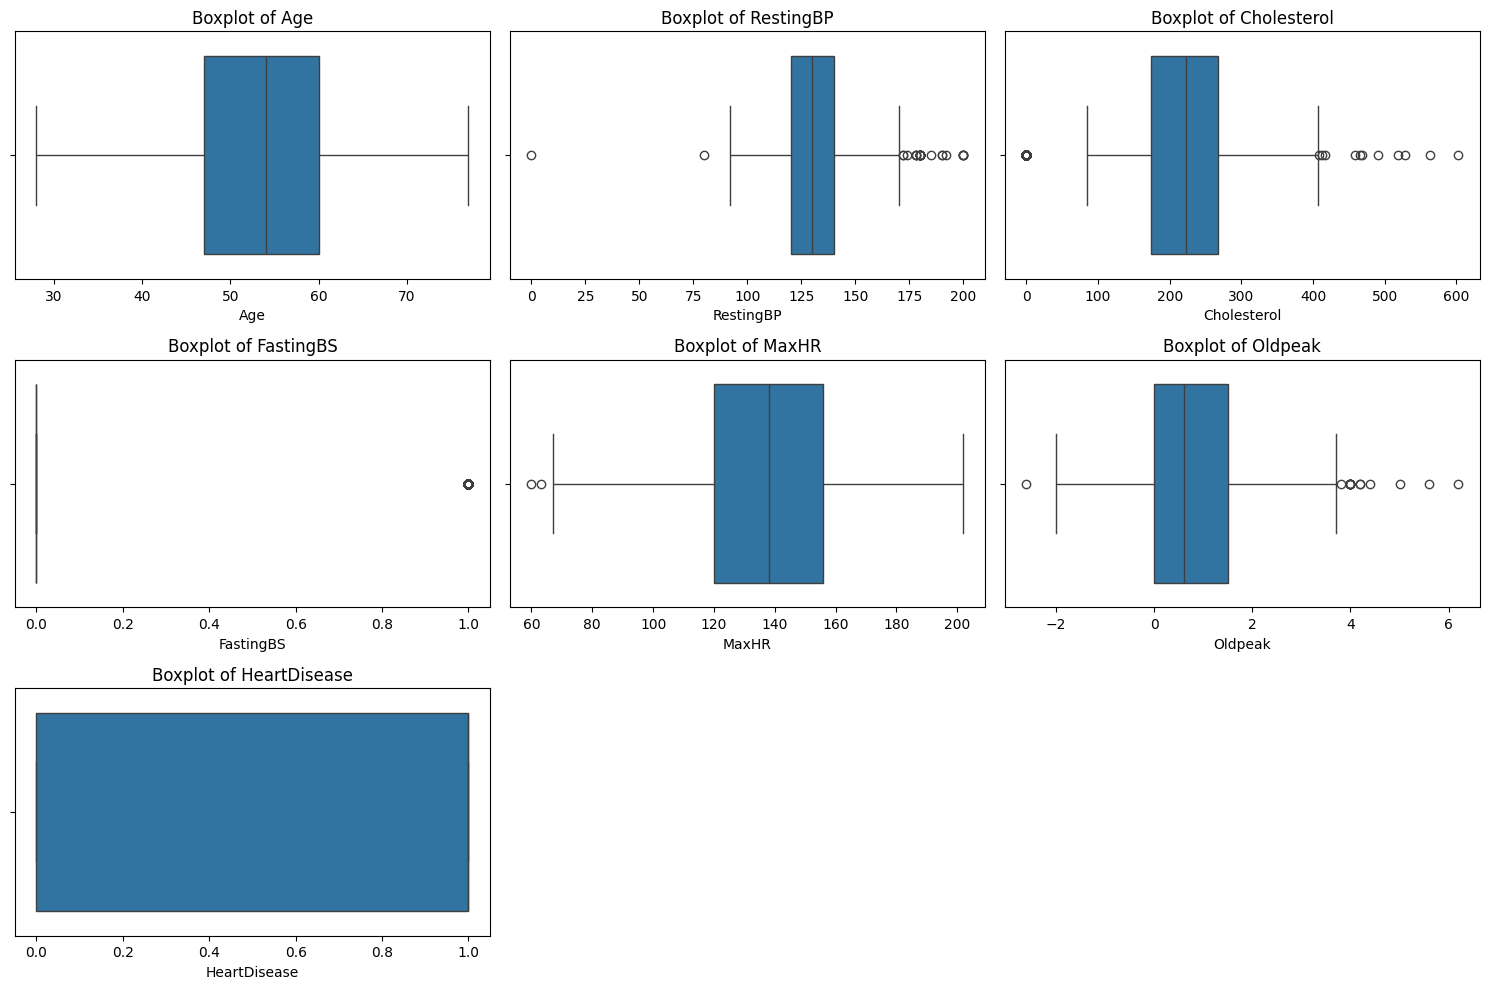

In [13]:
#1. إنشاء رسمة بيانية للأعمدة الرقمية
plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_df, 1):
    plt.subplot(3, 3, i) # تقسيم الشاشة لعدة رسومات صغيرة
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

الملخص: يعرض هذا الكود اكتشاف القيم الشاذة باستخدام الرسم البياني الصندوقي قبل المعالجة

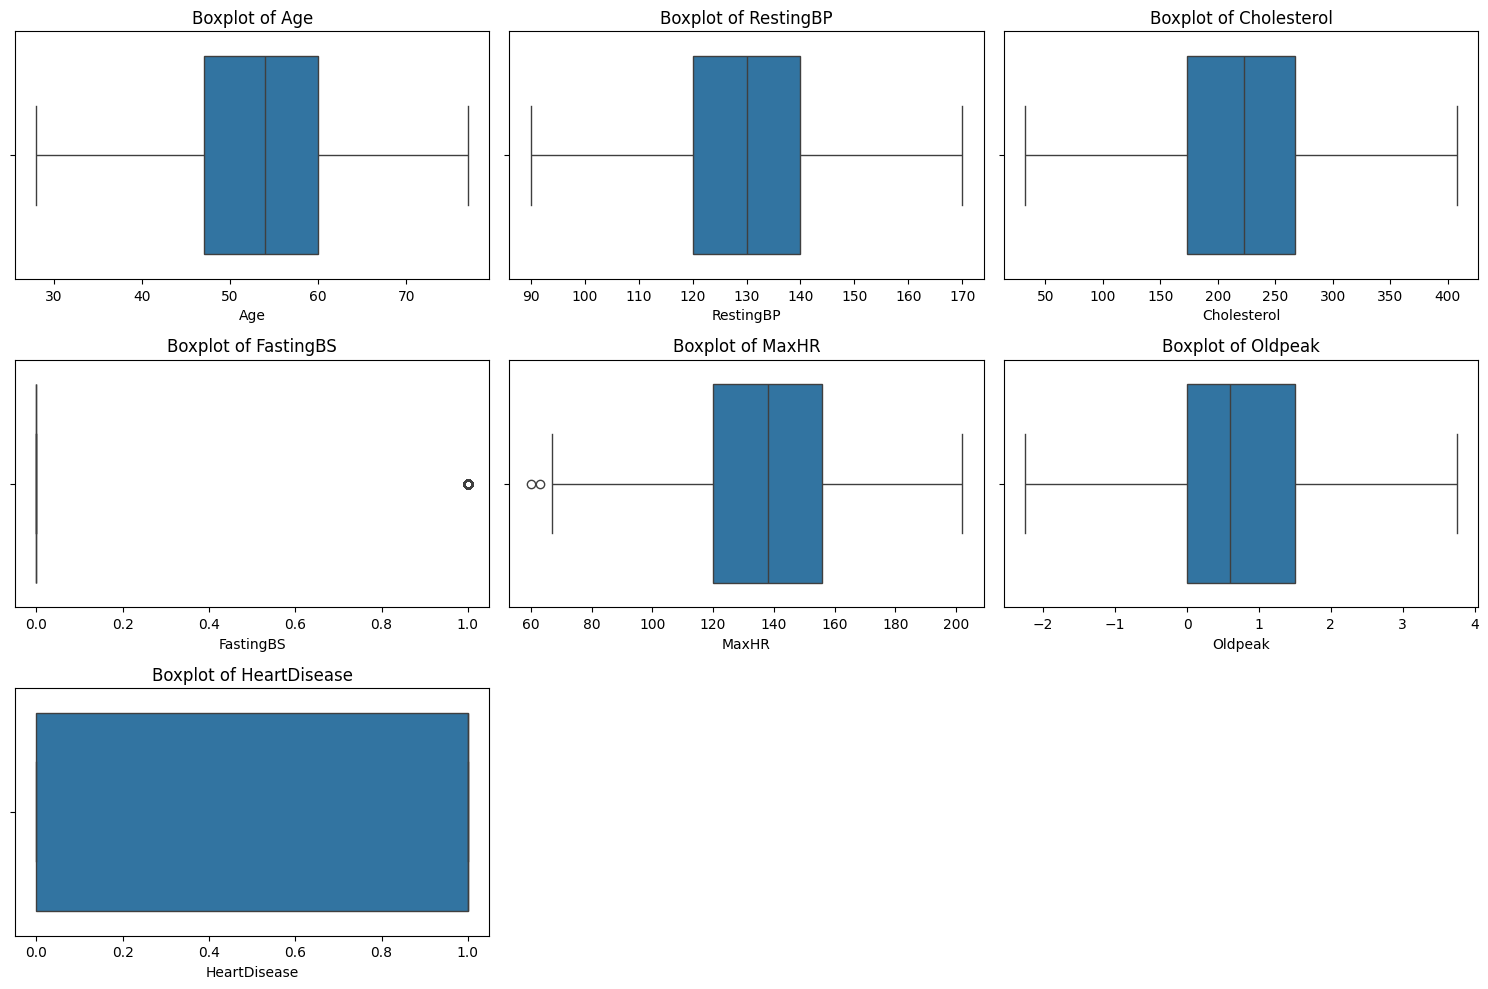

In [14]:
# 2. IQR معالجة القيم الشاذة عن طريق التقييد بناءً على حدود

def cap_outliers(df, column):    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    # تحديد الحد الأدنى والأعلى للقيم الطبيعية
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # تقييد (تسقيف) القيم الشاذة
    df[column] = df[column].clip(lower=lower, upper=upper)
    return df

# الأعمدة التي تحتوي على قيم شاذة 
cols = ['RestingBP', 'Cholesterol', 'Oldpeak']

# تطبيق معالجة القيم الشاذة على كل عمود
for col in cols:
    df = cap_outliers(df, col)

# الرسومات بعد معالجة القيم الشاذة
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_df, 1):
    plt.subplot(3, 3, i) # تقسيم الشاشة لعدة رسومات صغيرة
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

الملخص: يعرض هذا الكود معالجة القيم الشاذة
ويساعد تنظيف القيم الشاذة في تحسين أداء دقة النماذج وحمايتها من الانحياز

**3. Checking Duplicate Rows**

In [15]:
# فحص عدد الصفوف المكررة 
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows : ", duplicate_count,)


Number of duplicate rows :  0


الملخص: يوضح هذا الكود التحقق من وجود أي صفوف مكررة داخل مجموعة البيانات 
ويساعد على ضمان جودة البياناتومنع تكرار نفس المعطيات
الذي قد تسبب في تضخيم النتائج وتدريب النموذج بشكل خاطئ

**4. Checking Categorical Variables using unique()**

In [16]:
#تحديد الأعمدة النصية في البيانات
categorical_cols = df.select_dtypes(include=['object']).columns

print("Unique values in categorical columns :")
for col in categorical_cols:
    print("Column '", col, "': ", df[col].unique())



Unique values in categorical columns :
Column ' Sex ':  ['M' 'F']
Column ' ChestPainType ':  ['ATA' 'NAP' 'ASY' 'TA']
Column ' RestingECG ':  ['Normal' 'ST' 'LVH']
Column ' ExerciseAngina ':  ['N' 'Y']
Column ' ST_Slope ':  ['Up' 'Flat' 'Down']


الملخص: يعرض هذا الكود القيم الفريدة داخل المتغيرات الفئوية
ويساعد على التأكد من اتساق النصوص وتوحيدها وخلوها من الأخطاء الإملائية أو المسافات الزائدة 
قبل تحويلها إلى أرقام في مرحلة الترميز 

## Section 4 : Data Preprocessing &  Training Preparation

**Step 1: One-Hot Encoding**

In [17]:
# تحويل المتغيرات الفئوية إلى رقمية باستخدام One-Hot Encoding
# نستخدم drop_first=True لتجنب مشكلة الـ Multicollinearity
df_encoded = pd.get_dummies(df, drop_first=True)

# عرض أول 5 صفوف للتأكد من نجاح العملية
df_encoded.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True


التوضيح : في هذه الخطوة، نقوم بتحويل المتغيرات النصية إلى قيم رقمية لكي يتمكن الموديل من فهمها ومعالجتها.

**Step 2: Splitting Data**

In [18]:
# تحديد المتغيرات المستقلة (X) والمتغير التابع (y)
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

# تقسيم البيانات إلى تدريب واختبار (80% تدريب، 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# التأكد من تقسيم البيانات بشكل صحيح
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (734, 15)
Testing set shape: (184, 15)


التوضيح : هنا نقوم بفصل المتغير المستهدف (الذي نريد التنبؤ به) عن بقية المتغيرات، ثم تقسيم البيانات إلى مجموعة للتدريب ومجموعة للاختبار.

**Step 3: Feature Scaling**

In [19]:
# تهيئة الـ scaler
scaler = StandardScaler()

# تطبيق التحجيم على بيانات التدريب والاختبار
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# عرض عينة من البيانات بعد التحجيم
print("تم تحجيم البيانات بنجاح.")

تم تحجيم البيانات بنجاح.


التوضيح :لضمان أن جميع الميزات لها نفس التأثير على الموديل، نقوم بعمل Scaling للمتغيرات الرقمية باستخدام StandardScaler.

 ## Section 5: Training & Prediction

**في هذا القسم اخترنا نموذجين خطي(الانحدار اللوجيستي) وغير خطي(شجره القرار) لاجل المقارنه بين أدائهم وتحليل ايهما يقدم نتائج افضل لمشكله امراض القلب**

 هنا بنخليه يختار افضل عمق واقصى عدد للتكرارت وبعدها يبدا التدريب على اساسهم

In [20]:
import warnings
from sklearn.exceptions import ConvergenceWarning

log_max_iter = 100
log_converged = False

while not log_converged:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)

        model_test = LogisticRegression(max_iter=log_max_iter)
        model_test.fit(X_train, y_train)


        if not any(isinstance(warn.message, ConvergenceWarning) for warn in w):
            log_converged = True
            print(f" Logistic Regression max iter = {log_max_iter}")
        else:
            log_max_iter += 100


 Logistic Regression max iter = 1100


هنا عرضنا افضل عدد تكرارات للانحدار اللوجيستي

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

best_depth = 1
best_score = 0
depth = 1
improving = True

while improving:
    temp_tree = DecisionTreeClassifier(max_depth=depth, random_state=50)
    temp_tree.fit(X_train, y_train)
    score = temp_tree.score(X_test, y_test)

    # إذا الأداء تحسن → نحدث أفضل قيمة
    if score > best_score:
        best_score = score
        best_depth = depth
        depth += 1   # نزيد العمق ونكمل
    else:
        improving = False   # الأداء نزل → نوقف

print(f" max_depth = {best_depth} accuracy = {best_score}")


 max_depth = 4 accuracy = 0.875


وهنا افضل عمق لشجره القرار

**Training**

In [22]:
# تدريب اللوجستك  
log_model = LogisticRegression(max_iter=log_max_iter, random_state=50)
log_model.fit(X_train, y_train)

# تدريب شجرة القرار  
tree_model = DecisionTreeClassifier(max_depth=best_depth, random_state=50)
tree_model.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=4, random_state=50)

هنا سوينا تدريب للنموذجين بناء على العمق وعدد التكرارات الي اخترناهم

**التنبؤ**

In [23]:
# تنبؤات اللوجستك
y_pred_log = log_model.predict(X_test)
print(f"تنبؤات اللوجيستك{y_pred_log[:20]}")
# تنبؤات شجرة القرار
y_pred_tree = tree_model.predict(X_test)
print(f"تنبؤات شجره القرار{y_pred_tree[:20]}")

تنبؤات اللوجيستك[0 0 1 1 0 1 1 0 1 1 1 0 1 0 1 1 0 1 1 0]
تنبؤات شجره القرار[0 1 1 1 0 1 1 0 1 1 1 0 0 0 1 1 0 0 1 0]


هنا سوينا التنبؤ وعرضت اول 20 تنبؤ منهم

In [24]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#نعرض النتايج في جدول مرتب
def evaluate_pretty(y_test, y_pred_log, y_pred_tree):
    results = {
        "Model": ["Logistic Regression", "Decision Tree"],
        "Accuracy": [
            accuracy_score(y_test, y_pred_log),
            accuracy_score(y_test, y_pred_tree)
        ],
        "Precision": [
            precision_score(y_test, y_pred_log),
            precision_score(y_test, y_pred_tree)
        ],
        "Recall": [
            recall_score(y_test, y_pred_log),
            recall_score(y_test, y_pred_tree)
        ],
        "F1-score": [
            f1_score(y_test, y_pred_log),
            f1_score(y_test, y_pred_tree)
        ]
    }

    df = pd.DataFrame(results)
    return df

evaluate_pretty(y_test, y_pred_log, y_pred_tree)


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.853261,0.900000,0.841121,0.869565
1,Decision Tree,0.875000,0.903846,0.878505,0.890995


مما نلاحظه في النتائج نموذج شجره القرار هو الافضل في جميع المقايسس وهذا يعني انه اكثر ملائمه لتشخيص امراض القلب

In [25]:
# Training Accuracy
train_pred_lr = log_model.predict(X_train)
train_accuracy_lr = accuracy_score(y_train, train_pred_lr)

# Test Accuracy (Prediction Results)
test_pred_lr = log_model.predict(X_test)
test_accuracy_lr = accuracy_score(y_test, test_pred_lr)

print("Logistic Regression:")
print("Training Accuracy:", train_accuracy_lr)
print("Test Accuracy:", test_accuracy_lr)


Logistic Regression:
Training Accuracy: 0.8719346049046321
Test Accuracy: 0.8532608695652174


هنا طبعنا الفرق بين نتائج النتريب ونتائج الاختبار في نموذج اللوجاريثم

In [26]:
# Training Accuracy
train_pred_dt = tree_model.predict(X_train)
train_accuracy_dt = accuracy_score(y_train, train_pred_dt)

# Test Accuracy (Prediction Results)
test_pred_dt = tree_model.predict(X_test)
test_accuracy_dt = accuracy_score(y_test, test_pred_dt)

print("\nDecision Tree:")
print("Training Accuracy:", train_accuracy_dt)
print("Test Accuracy:", test_accuracy_dt)



Decision Tree:
Training Accuracy: 0.8801089918256131
Test Accuracy: 0.875


وهنا طبعنا الفرق بين نتائج النتريب ونتائج الاختبار في نموذج شجره القرار

 overfittingنلاحظ انه الاختلاف بينهم بسيط وعدم وجود 